# Welding Defect Detection — Improved Low-Data Pipeline (v2)

**Starting point:** 6 raw, high-resolution weld inspection images with YOLO bounding-box labels
(exported from Roboflow, already split into `train / valid / test` *before* any patching — this is
important and is preserved below so we never leak the same source image across splits).

**What changed vs. the original notebook, and why:**

| Area | Original | v2 (this notebook) |
|---|---|---|
| Patching | Single tile size (640px), 25% overlap, **only tiles containing a defect kept** | Multi-scale tiles (384/512/640), defect-centered "zoom" crops, **hard-negative background patches kept at a controlled ratio** so the model learns what is *not* a defect |
| Augmentation | Hand-rolled affine warp, 1 augmented copy per patch | Albumentations pipeline (geometric + photometric + noise + cutout), **8–12 augmented copies per positive patch**, plus **copy-paste synthesis** (pasting real defect crops onto new backgrounds) — the single highest-leverage trick for 6-image datasets |
| Models | YOLO11n only | **YOLO11n + YOLO11s ensemble** (Weighted Boxes Fusion) + **ResNet18 classifier** used as a false-positive filter + optional **U-Net (ResNet34 encoder)** segmentation head, fused into the ensemble |
| Inference | Plain `model.predict` + separate SAHI demo | SAHI sliced inference **for every model**, then WBF ensembling, then ResNet verification |
| Validation | Single train/valid/test split | Same leak-safe split, **plus grouped k-fold cross-validation** across the 6 source images so the accuracy number you report isn't a fluke of one split |
| Evaluation | mAP only | mAP50 / mAP50-95 / P / R **per model and for the ensemble**, plus an image-level "did we catch the defect" accuracy that is easier to communicate to non-CV stakeholders |

> **Honest expectation-setting (read this first):** with 6 source images, any number you get — 70%,
> 90%, whatever — has a huge confidence interval. The techniques below will measurably help, but the
> single biggest lever you have is *more images* or reframing this as **anomaly detection**
> (one-class, e.g. PatchCore/PaDiM via the `anomalib` library) instead of supervised detection, since
> anomaly detection only needs *normal* (defect-free) weld images to train on. See the final section
> for a short discussion.


## 0. Setup & Config

In [ ]:
# Run once in Colab. Skip if running locally / files already present.
from google.colab import files
uploaded = files.upload()  # upload your roboflow-exported yolov11 zip (e.g. new_data.yolov11.zip)


Saving new_data.yolov11.zip to new_data.yolov11.zip


In [ ]:
import os, glob, json, math, random, shutil, zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# ---------------------------------------------------------------------------
# CENTRAL CONFIG — tweak everything here, nothing else in the notebook
# ---------------------------------------------------------------------------
CFG = dict(
    zip_path      = "/content/new_data.yolov11.zip",
    raw_dir       = "/content/CRACK_DATASET",          # extracted roboflow export
    patched_dir   = "/content/CRACK_PATCHED_V2",        # improved patches live here
    final_dir     = "/content/FINAL_YOLO_V2",           # ready-to-train YOLO dataset
    class_names   = ["defect"],

    # --- multi-scale patching ---
    tile_sizes    = [384, 512, 640],
    overlap       = 0.30,                # fraction overlap between adjacent tiles
    min_box_keep_ratio = 0.30,           # keep a clipped box only if >=30% of it survives
    min_box_px    = 4,                   # discard boxes smaller than this after clipping

    # --- defect-centered "zoom" crops (guarantee the defect is never cut off) ---
    zoom_crop_sizes   = [256, 384],
    zoom_jitter_frac  = 0.15,            # random offset of the crop center, as a fraction of crop size
    zoom_crops_per_box = 3,

    # --- hard negatives (background-only tiles, no defect) ---
    negative_to_positive_ratio = 0.5,    # e.g. 0.5 -> 1 negative for every 2 positive patches

    # --- offline augmentation ---
    augs_per_positive = 10,
    augs_per_negative = 3,
    copy_paste_per_image = 6,            # synthetic positives made by pasting a defect crop onto a background

    seed = 42,
)

os.makedirs(CFG["patched_dir"], exist_ok=True)
os.makedirs(CFG["final_dir"], exist_ok=True)

with zipfile.ZipFile(CFG["zip_path"], "r") as zf:
    zf.extractall(CFG["raw_dir"])

for split in ["train", "valid", "test"]:
    img_dir = os.path.join(CFG["raw_dir"], split, "images")
    lbl_dir = os.path.join(CFG["raw_dir"], split, "labels")
    if os.path.isdir(img_dir):
        print(f"{split:6} -> images: {len(os.listdir(img_dir)):3} | labels: {len(os.listdir(lbl_dir)):3}")
    else:
        print(f"{split:6} -> (not present in this export)")


train  -> images:   4 | labels:   4
valid  -> images:   1 | labels:   1
test   -> images:   1 | labels:   1


In [ ]:
!pip install -q -U ultralytics albumentations ensemble-boxes sahi segmentation-models-pytorch
!nvidia-smi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 232.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 12.4 MB/s eta 0:00:00
Wed Sep  9 14:55:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                            

## 1. Sanity check: leak-safe split

Because patches/crops are generated **after** the train/valid/test split (not before), every patch
inherits the split of its parent image. Confirm below that no source-image stem appears in more than
one split — this is the single most important thing to get right with so little data, otherwise your
reported test accuracy is meaningless (the model would effectively be tested on crops of an image it
already trained on).

In [ ]:
def stems(split):
    d = os.path.join(CFG["raw_dir"], split, "images")
    if not os.path.isdir(d):
        return set()
    return {os.path.splitext(f)[0] for f in os.listdir(d) if f.lower().endswith((".jpg", ".jpeg", ".png"))}

train_stems, valid_stems, test_stems = stems("train"), stems("valid"), stems("test")
print("train:", train_stems)
print("valid:", valid_stems)
print("test :", test_stems)

overlap_tv = train_stems & valid_stems
overlap_tt = train_stems & test_stems
overlap_vt = valid_stems & test_stems
assert not overlap_tv and not overlap_tt and not overlap_vt, "LEAKAGE DETECTED between splits!"
print("\nNo leakage between splits — safe to proceed.")


train: {'SV 2208 DA 01 TSS LS00005_png.rf.lFr7ORnsk1VpOU7MLcIu', 'SV 2208 DA 02 TSS LS D-E_png.rf.dvNyRnsuP6wcWUKBGiy5', 'SV 2208 DA 01 TSS LS C-D_png.rf.uRD1JJuShR0rCSI1VZMB', 'GY HS200 JM MCW-106 00004_png.rf.vaNG1RVo4yGXYfmGJSKZ'}
valid: {'SV 4483 RS2 MC-05 CS00008_png.rf.cCFFvdkUljOtpAuLBFOp'}
test : {'SV 4483 RS2 MC-16 CS00010_png.rf.cfKCqmTTalGQfDb7puBo'}

No leakage between splits — safe to proceed.


## 2. Visualize the raw images

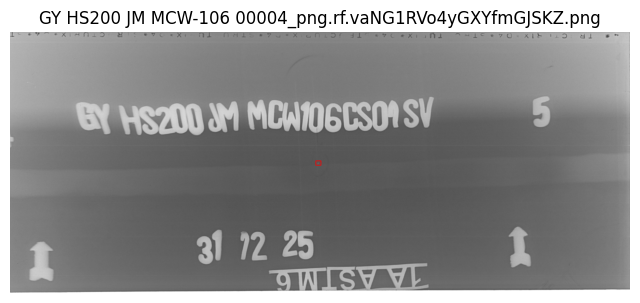

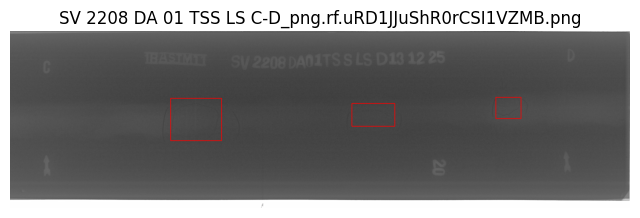

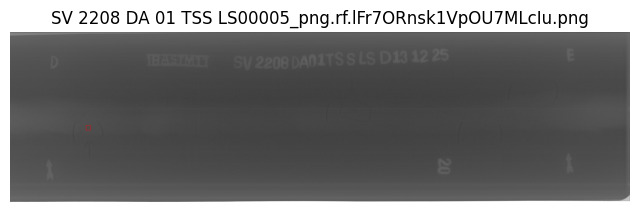

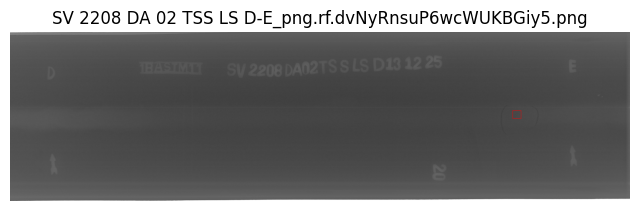

In [ ]:
def yolo_to_pixels(line, w, h):
    cls, xc, yc, bw, bh = map(float, line.split())
    xc, yc, bw, bh = xc*w, yc*h, bw*w, bh*h
    return int(cls), int(xc-bw/2), int(yc-bh/2), int(xc+bw/2), int(yc+bh/2)

def show_with_boxes(image_path, label_path, title=""):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                if len(line.split()) != 5:
                    continue
                cls, x1, y1, x2, y2 = yolo_to_pixels(line, w, h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
    plt.figure(figsize=(8, 6)); plt.imshow(img); plt.title(title); plt.axis("off"); plt.show()

img_dir = os.path.join(CFG["raw_dir"], "train", "images")
lbl_dir = os.path.join(CFG["raw_dir"], "train", "labels")
for f in sorted(os.listdir(img_dir))[:6]:
    show_with_boxes(os.path.join(img_dir, f),
                     os.path.join(lbl_dir, os.path.splitext(f)[0] + ".txt"), f)


## 3. Improved patching

Three complementary patch types are generated per split:

1. **Multi-scale tiled patches** — sliding window at several tile sizes (384/512/640) with overlap, so
   the model sees defects at different relative scales instead of a single fixed scale.
2. **Defect-centered "zoom" crops** — a crop is placed directly on top of each ground-truth box (with a
   small random jitter) so the defect is *never* clipped or split across a tile boundary. This is the
   #1 fix for tiny datasets: it guarantees every defect instance produces several clean, centered
   examples instead of relying on luck from a sliding window.
3. **Hard-negative background tiles** — a controlled number of defect-free tiles are *kept* (the
   original notebook discarded 100% of these). Without negatives the detector never learns what
   background weld/metal texture looks like and tends to over-predict on the test set.


In [ ]:
def load_boxes(label_path):
    boxes = []
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                p = line.split()
                if len(p) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, p)
                boxes.append([int(cls), xc, yc, bw, bh])
    return boxes

def norm_to_pixel(box, w, h):
    cls, xc, yc, bw, bh = box
    return cls, (xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h

def clip_box_to_tile(cls, bx1, by1, bx2, by2, x, y, x_end, y_end, min_ratio, min_px):
    ix1, iy1 = max(bx1, x), max(by1, y)
    ix2, iy2 = min(bx2, x_end), min(by2, y_end)
    iw, ih = ix2 - ix1, iy2 - iy1
    if iw <= min_px or ih <= min_px:
        return None
    orig_area = max((bx2-bx1)*(by2-by1), 1)
    if (iw*ih)/orig_area < min_ratio:
        return None
    tw, th = x_end - x, y_end - y
    txc = ((ix1+ix2)/2 - x) / tw
    tyc = ((iy1+iy2)/2 - y) / th
    bwn = iw / tw
    bhn = ih / th
    return f"{cls} {txc:.6f} {tyc:.6f} {bwn:.6f} {bhn:.6f}"

def save_patch(img, labels, out_img_dir, out_lbl_dir, name):
    cv2.imwrite(os.path.join(out_img_dir, name + ".jpg"), img)
    with open(os.path.join(out_lbl_dir, name + ".txt"), "w") as f:
        f.write("\n".join(labels))

def generate_patches(split):
    image_dir = os.path.join(CFG["raw_dir"], split, "images")
    label_dir = os.path.join(CFG["raw_dir"], split, "labels")
    if not os.path.isdir(image_dir):
        return 0, 0
    out_img = os.path.join(CFG["patched_dir"], split, "images")
    out_lbl = os.path.join(CFG["patched_dir"], split, "labels")
    os.makedirs(out_img, exist_ok=True); os.makedirs(out_lbl, exist_ok=True)

    n_pos = n_neg = 0
    image_files = sorted(f for f in os.listdir(image_dir) if f.lower().endswith((".jpg", ".jpeg", ".png")))

    for image_name in image_files:
        base = os.path.splitext(image_name)[0]
        img = cv2.imread(os.path.join(image_dir, image_name))
        if img is None:
            continue
        h, w = img.shape[:2]
        raw_boxes = load_boxes(os.path.join(label_dir, base + ".txt"))
        pixel_boxes = [norm_to_pixel(b, w, h) for b in raw_boxes]

        # ---- 1) multi-scale sliding-window tiles ----
        candidate_negatives = []
        for tile in CFG["tile_sizes"]:
            stride = max(int(tile * (1 - CFG["overlap"])), 1)
            ys = list(range(0, max(h - tile, 0) + 1, stride)) or [0]
            xs = list(range(0, max(w - tile, 0) + 1, stride)) or [0]
            if h > tile and ys[-1] != h - tile: ys.append(h - tile)
            if w > tile and xs[-1] != w - tile: xs.append(w - tile)

            for y in ys:
                for x in xs:
                    x_end, y_end = min(x + tile, w), min(y + tile, h)
                    tile_img = img[y:y_end, x:x_end]
                    if tile_img.shape[0] < 32 or tile_img.shape[1] < 32:
                        continue
                    new_labels = []
                    for cls, bx1, by1, bx2, by2 in pixel_boxes:
                        lbl = clip_box_to_tile(cls, bx1, by1, bx2, by2, x, y, x_end, y_end,
                                                CFG["min_box_keep_ratio"], CFG["min_box_px"])
                        if lbl:
                            new_labels.append(lbl)
                    name = f"{base}_t{tile}_x{x}_y{y}"
                    if new_labels:
                        save_patch(tile_img, new_labels, out_img, out_lbl, name)
                        n_pos += 1
                    else:
                        candidate_negatives.append((tile_img.copy(), name))

        # ---- 2) defect-centered zoom crops ----
        for bi, (cls, bx1, by1, bx2, by2) in enumerate(pixel_boxes):
            box_w, box_h = bx2 - bx1, by2 - by1
            cx, cy = (bx1+bx2)/2, (by1+by2)/2
            for size in CFG["zoom_crop_sizes"]:
                size = max(size, int(box_w*1.4), int(box_h*1.4))  # never crop smaller than the box
                for _ in range(CFG["zoom_crops_per_box"]):
                    jx = random.uniform(-1, 1) * CFG["zoom_jitter_frac"] * size
                    jy = random.uniform(-1, 1) * CFG["zoom_jitter_frac"] * size
                    x = int(np.clip(cx - size/2 + jx, 0, max(w - size, 0)))
                    y = int(np.clip(cy - size/2 + jy, 0, max(h - size, 0)))
                    x_end, y_end = min(x+size, w), min(y+size, h)
                    crop = img[y:y_end, x:x_end]
                    if crop.shape[0] < 32 or crop.shape[1] < 32:
                        continue
                    new_labels = []
                    for c2, cx1, cy1, cx2, cy2 in pixel_boxes:
                        lbl = clip_box_to_tile(c2, cx1, cy1, cx2, cy2, x, y, x_end, y_end,
                                                CFG["min_box_keep_ratio"], CFG["min_box_px"])
                        if lbl:
                            new_labels.append(lbl)
                    if new_labels:
                        name = f"{base}_zoom{size}_b{bi}_x{x}_y{y}"
                        save_patch(crop, new_labels, out_img, out_lbl, name)
                        n_pos += 1

        # ---- 3) hard negatives, capped at a controlled ratio ----
        random.shuffle(candidate_negatives)
        n_take = int(n_pos * CFG["negative_to_positive_ratio"]) - n_neg
        for neg_img, name in candidate_negatives[:max(n_take, 0)]:
            save_patch(neg_img, [], out_img, out_lbl, name)
            n_neg += 1

    print(f"{split.upper():6} -> positive patches: {n_pos:4} | negative patches: {n_neg:4}")
    return n_pos, n_neg

for split in ["train", "valid", "test"]:
    generate_patches(split)


TRAIN  -> positive patches:   81 | negative patches:   40
VALID  -> positive patches:   11 | negative patches:    5
TEST   -> positive patches:   14 | negative patches:    7


### Visual check of the new patches (positives with boxes drawn, and negatives)

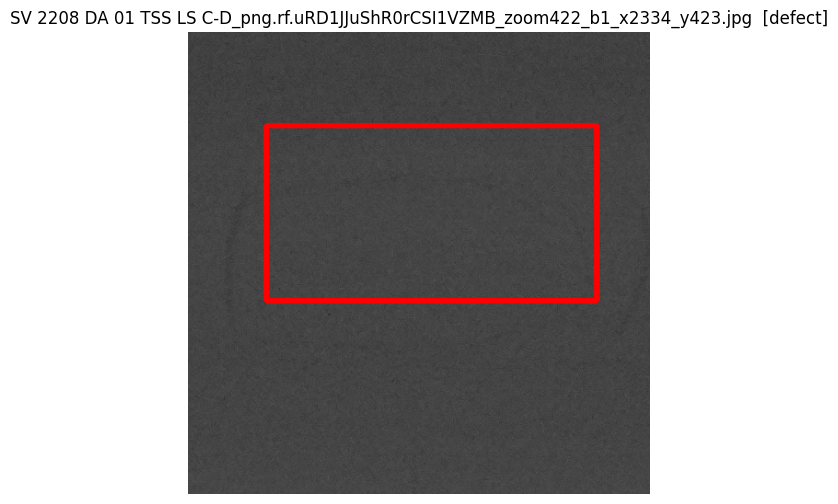

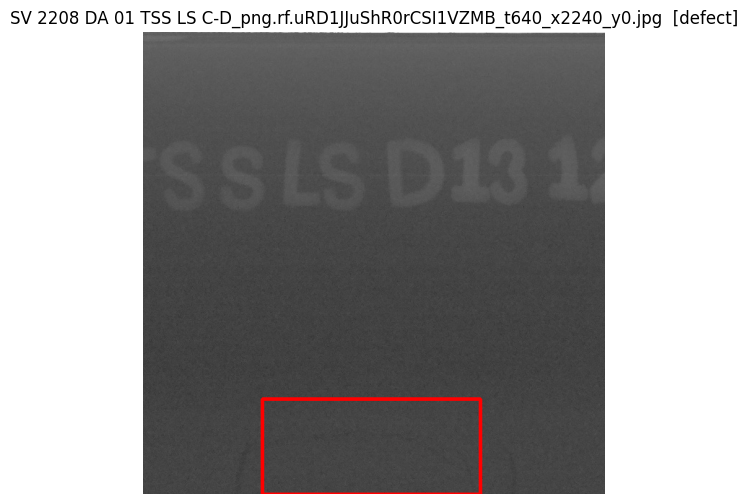

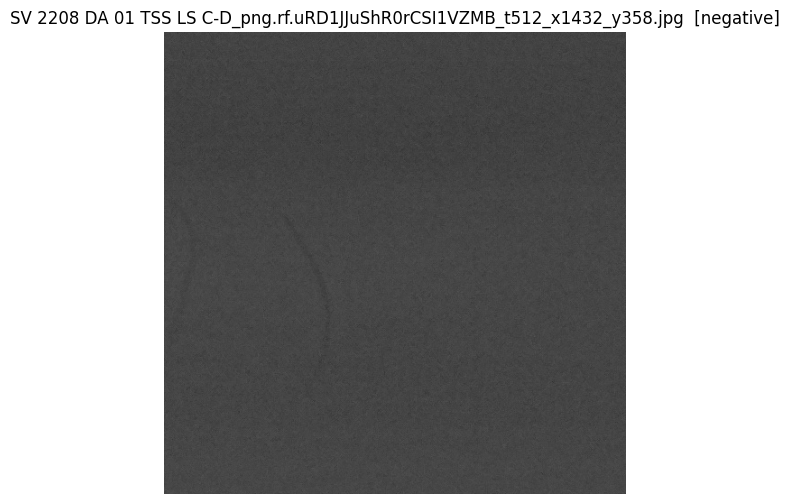

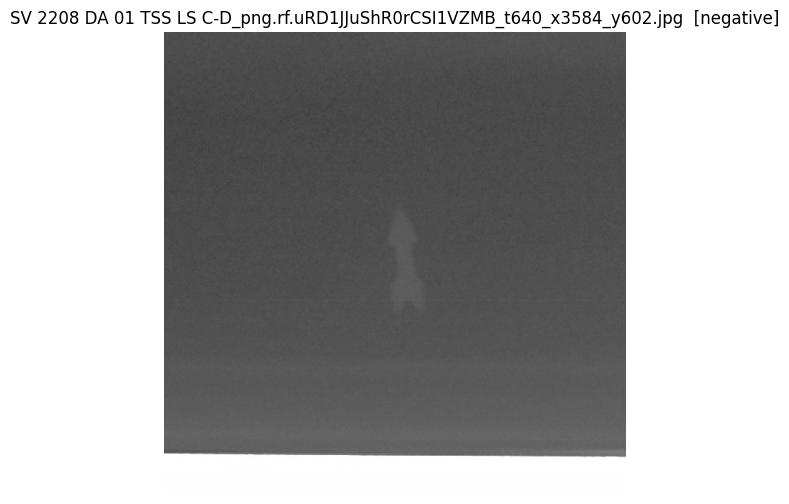

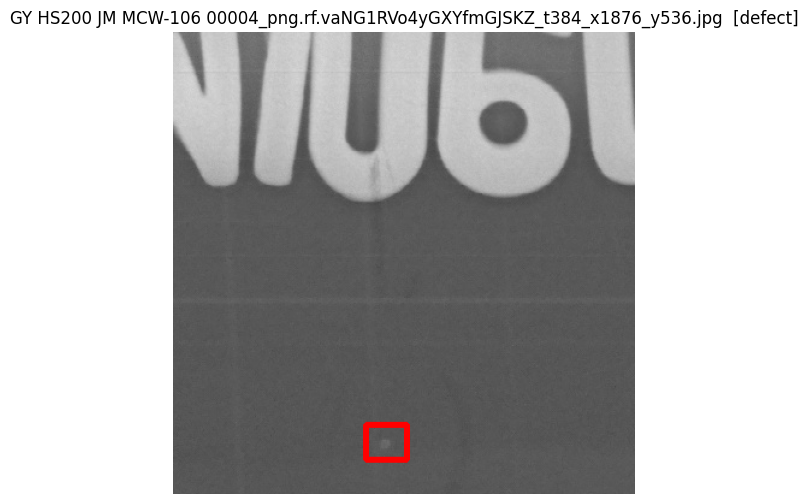

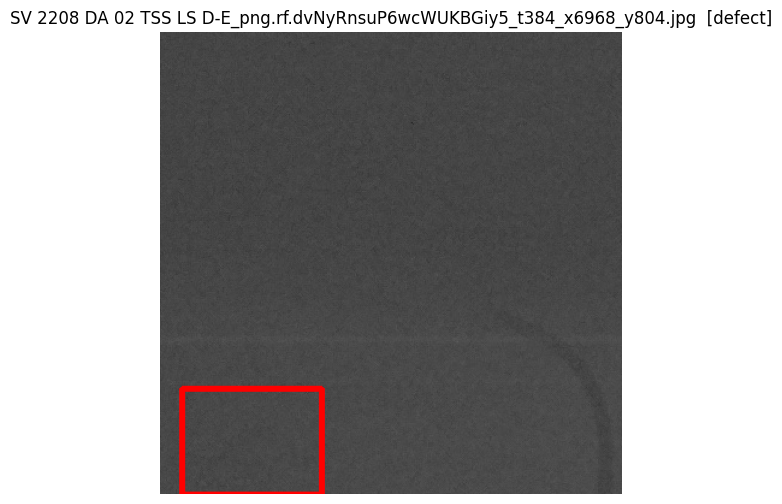

In [ ]:
def show_random_patches(split, n=6):
    img_dir = os.path.join(CFG["patched_dir"], split, "images")
    lbl_dir = os.path.join(CFG["patched_dir"], split, "labels")
    files = os.listdir(img_dir)
    random.shuffle(files)
    for f in files[:n]:
        lp = os.path.join(lbl_dir, os.path.splitext(f)[0] + ".txt")
        has_box = os.path.exists(lp) and os.path.getsize(lp) > 0
        show_with_boxes(os.path.join(img_dir, f), lp, f"{f}  [{'defect' if has_box else 'negative'}]")

show_random_patches("train", n=6)


## 4. Offline augmentation (Albumentations) + copy-paste synthesis

Two engines:

* **Standard augmentation** — a bbox-aware Albumentations `Compose` combining geometric transforms
  (flips, safe rotation, shift/scale/rotate, elastic/grid distortion) with photometric transforms
  (brightness/contrast, CLAHE, blur, Gaussian/ISO noise, coarse dropout). Boxes are transformed
  automatically and dropped if they fall outside the frame — far more robust than the hand-rolled
  affine warp in the original notebook.
* **Copy-paste synthesis** — crops the actual defect pixels out of a positive patch and pastes them
  (with random scale/rotation/blend) onto a *different* background patch. This directly multiplies the
  number of distinct backgrounds each defect appears against, which is usually worth more than another
  generic rotation when you only have a handful of defect instances to begin with.


In [ ]:
import albumentations as A

TRAIN_IMG = os.path.join(CFG["patched_dir"], "train", "images")
TRAIN_LBL = os.path.join(CFG["patched_dir"], "train", "labels")
AUG_IMG   = os.path.join(CFG["patched_dir"], "train_aug", "images")
AUG_LBL   = os.path.join(CFG["patched_dir"], "train_aug", "labels")
os.makedirs(AUG_IMG, exist_ok=True); os.makedirs(AUG_LBL, exist_ok=True)

aug_pipeline = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12, rotate_limit=15,
                        border_mode=cv2.BORDER_CONSTANT, p=0.7),
    A.OneOf([
        A.ElasticTransform(alpha=20, sigma=5, p=1.0),
        A.GridDistortion(num_steps=5, distort_limit=0.15, p=1.0),
        A.OpticalDistortion(distort_limit=0.1, p=1.0),
    ], p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.7),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.OneOf([
        A.GaussNoise(var_limit=(5.0, 25.0), p=1.0),
        A.ISONoise(p=1.0),
        A.MultiplicativeNoise(multiplier=(0.9, 1.1), p=1.0),
    ], p=0.4),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        A.MotionBlur(blur_limit=5, p=1.0),
    ], p=0.2),
    A.CoarseDropout(max_holes=4, max_height=0.08, max_width=0.08, fill_value=0, p=0.3),
], bbox_params=A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3))


def read_yolo_labels(label_path):
    boxes, classes = [], []
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                p = line.split()
                if len(p) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, p)
                boxes.append([xc, yc, bw, bh])
                classes.append(int(cls))
    return boxes, classes


def write_yolo_labels(path, boxes, classes):
    with open(path, "w") as f:
        for (xc, yc, bw, bh), cls in zip(boxes, classes):
            f.write(f"{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")


patch_files = sorted(f for f in os.listdir(TRAIN_IMG) if f.lower().endswith((".jpg", ".jpeg", ".png")))
positives, negatives = [], []
for f in patch_files:
    lp = os.path.join(TRAIN_LBL, os.path.splitext(f)[0] + ".txt")
    (positives if (os.path.exists(lp) and os.path.getsize(lp) > 0) else negatives).append(f)

print(f"Base positives: {len(positives)} | Base negatives: {len(negatives)}")

n_aug = 0
for f in positives:
    img = cv2.imread(os.path.join(TRAIN_IMG, f))
    boxes, classes = read_yolo_labels(os.path.join(TRAIN_LBL, os.path.splitext(f)[0] + ".txt"))
    if img is None or not boxes:
        continue
    for k in range(CFG["augs_per_positive"]):
        try:
            result = aug_pipeline(image=img, bboxes=boxes, class_labels=classes)
        except Exception:
            continue
        if not result["bboxes"]:
            continue  # skip if augmentation pushed every box out of frame
        name = f"{os.path.splitext(f)[0]}_aug{k}"
        cv2.imwrite(os.path.join(AUG_IMG, name + ".jpg"), result["image"])
        write_yolo_labels(os.path.join(AUG_LBL, name + ".txt"), result["bboxes"], result["class_labels"])
        n_aug += 1

for f in negatives:
    img = cv2.imread(os.path.join(TRAIN_IMG, f))
    if img is None:
        continue
    for k in range(CFG["augs_per_negative"]):
        try:
            result = aug_pipeline(image=img, bboxes=[], class_labels=[])
        except Exception:
            continue
        name = f"{os.path.splitext(f)[0]}_aug{k}"
        cv2.imwrite(os.path.join(AUG_IMG, name + ".jpg"), result["image"])
        write_yolo_labels(os.path.join(AUG_LBL, name + ".txt"), [], [])
        n_aug += 1

print(f"Albumentations augmentation complete. New patches created: {n_aug}")


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_624/2558146413.py:23: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 25.0), p=1.0),
/tmp/ipykernel_624/2558146413.py:31: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=4, max_height=0.08, max_width=0.08, fill_value=0, p=0.3),


Base positives: 81 | Base negatives: 40
Albumentations augmentation complete. New patches created: 854


In [ ]:
# ---- Copy-paste synthesis: paste real defect crops onto other backgrounds ----
def extract_defect_crops(files):
    crops = []
    for f in files:
        img = cv2.imread(os.path.join(TRAIN_IMG, f))
        boxes, classes = read_yolo_labels(os.path.join(TRAIN_LBL, os.path.splitext(f)[0] + ".txt"))
        if img is None:
            continue
        h, w = img.shape[:2]
        for (xc, yc, bw, bh), cls in zip(boxes, classes):
            x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
            x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
            x1, y1 = max(x1, 0), max(y1, 0)
            x2, y2 = min(x2, w), min(y2, h)
            if x2-x1 < 6 or y2-y1 < 6:
                continue
            crops.append((img[y1:y2, x1:x2].copy(), cls))
    return crops


def paste_crop(background, crop, cls):
    bg = background.copy()
    bh, bw = bg.shape[:2]
    scale = random.uniform(0.7, 1.3)
    ch, cw = crop.shape[:2]
    new_w, new_h = max(int(cw*scale), 4), max(int(ch*scale), 4)
    if new_w >= bw or new_h >= bh:
        return None
    resized = cv2.resize(crop, (new_w, new_h))
    angle = random.uniform(-20, 20)
    M = cv2.getRotationMatrix2D((new_w/2, new_h/2), angle, 1.0)
    resized = cv2.warpAffine(resized, M, (new_w, new_h), borderMode=cv2.BORDER_REFLECT)

    x = random.randint(0, bw - new_w)
    y = random.randint(0, bh - new_h)

    # feathered alpha blend so the paste doesn't look like a hard rectangle
    mask = np.zeros((new_h, new_w), dtype=np.float32)
    cv2.ellipse(mask, (new_w//2, new_h//2), (new_w//2, new_h//2), 0, 0, 360, 1.0, -1)
    mask = cv2.GaussianBlur(mask, (0, 0), sigmaX=max(new_w, new_h)*0.08)
    mask = mask[..., None]

    roi = bg[y:y+new_h, x:x+new_w].astype(np.float32)
    blended = roi * (1 - mask) + resized.astype(np.float32) * mask
    bg[y:y+new_h, x:x+new_w] = blended.astype(np.uint8)

    xc, yc = (x + new_w/2) / bw, (y + new_h/2) / bh
    bwn, bhn = new_w / bw, new_h / bh
    return bg, (xc, yc, bwn, bhn), cls


defect_crops = extract_defect_crops(positives)
print("Extracted defect crops for copy-paste:", len(defect_crops))

n_cp = 0
for f in negatives:
    bg = cv2.imread(os.path.join(TRAIN_IMG, f))
    if bg is None or not defect_crops:
        continue
    for k in range(CFG["copy_paste_per_image"]):
        crop, cls = random.choice(defect_crops)
        out = paste_crop(bg, crop, cls)
        if out is None:
            continue
        new_img, box, cls = out
        name = f"{os.path.splitext(f)[0]}_cp{k}"
        cv2.imwrite(os.path.join(AUG_IMG, name + ".jpg"), new_img)
        write_yolo_labels(os.path.join(AUG_LBL, name + ".txt"), [box], [cls])
        n_cp += 1

print("Copy-paste synthetic positives created:", n_cp)


Extracted defect crops for copy-paste: 81
Copy-paste synthetic positives created: 234


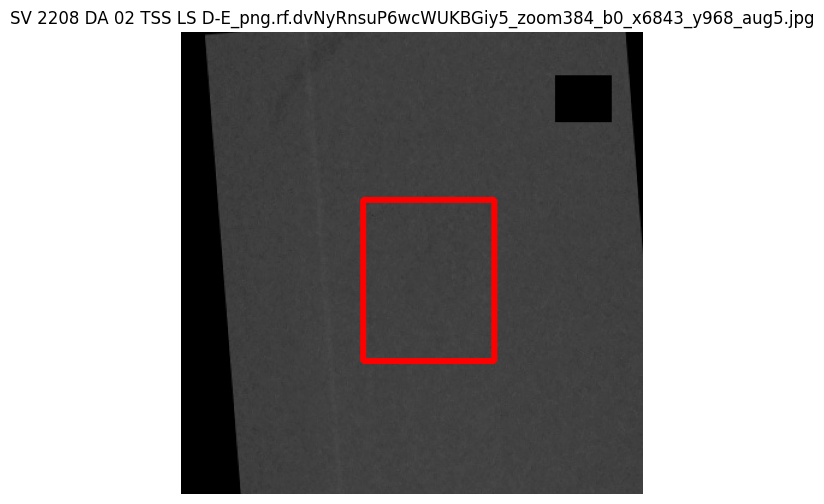

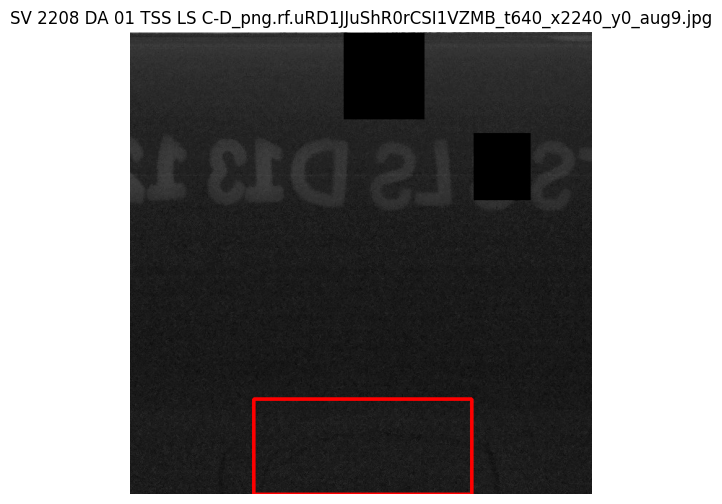

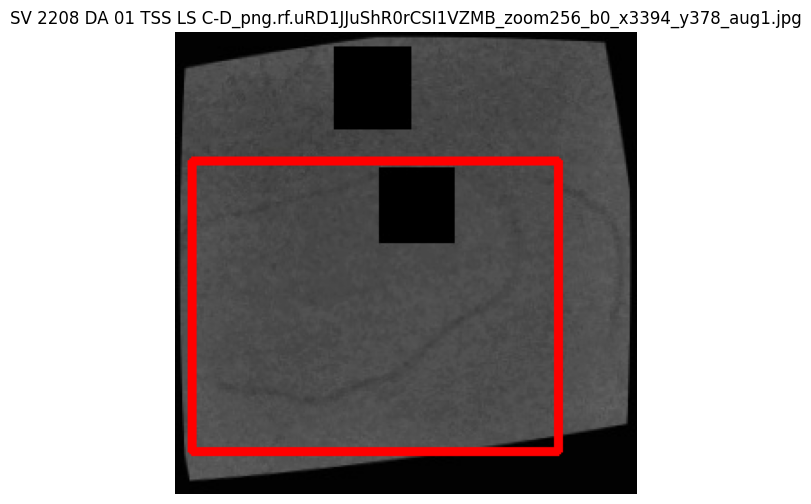

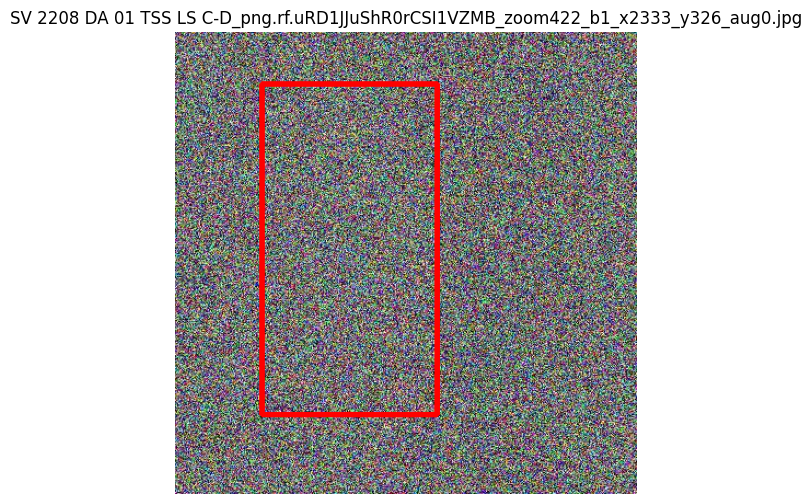

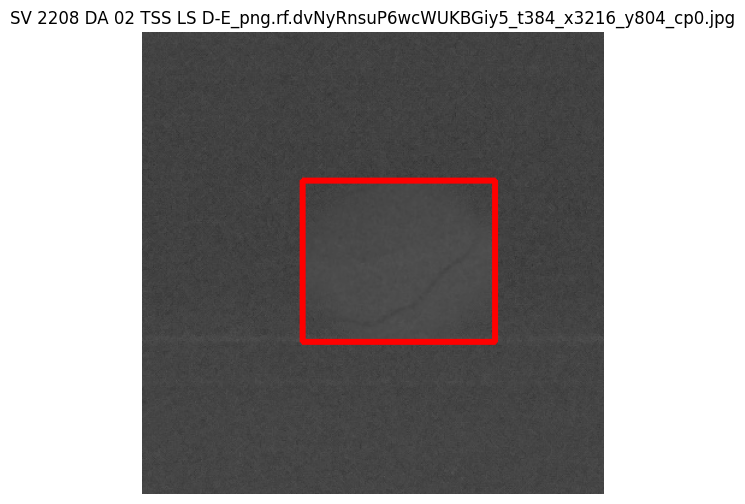

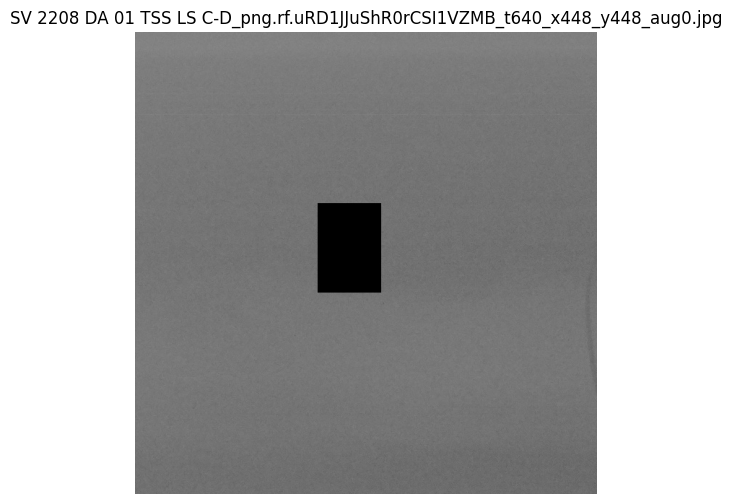

In [ ]:
show_random_patches_dir = lambda d, n=6: None  # placeholder, real viewer below

def show_random_from(img_dir, lbl_dir, n=6):
    files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    random.shuffle(files)
    for f in files[:n]:
        show_with_boxes(os.path.join(img_dir, f), os.path.join(lbl_dir, os.path.splitext(f)[0] + ".txt"), f)

show_random_from(AUG_IMG, AUG_LBL, n=6)


## 5. Assemble the final YOLO dataset

In [ ]:
FINAL = CFG["final_dir"]
for split in ["train", "valid", "test"]:
    os.makedirs(os.path.join(FINAL, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(FINAL, split, "labels"), exist_ok=True)

def copy_all(src_img, src_lbl, dst_img, dst_lbl):
    if not os.path.isdir(src_img):
        return
    for f in os.listdir(src_img):
        shutil.copy2(os.path.join(src_img, f), os.path.join(dst_img, f))
    for f in os.listdir(src_lbl):
        shutil.copy2(os.path.join(src_lbl, f), os.path.join(dst_lbl, f))

# train = base patches + albumentations aug + copy-paste
copy_all(os.path.join(CFG["patched_dir"], "train", "images"),
         os.path.join(CFG["patched_dir"], "train", "labels"),
         os.path.join(FINAL, "train", "images"), os.path.join(FINAL, "train", "labels"))
copy_all(AUG_IMG, AUG_LBL, os.path.join(FINAL, "train", "images"), os.path.join(FINAL, "train", "labels"))

# valid / test = base patches only (never augmented — must reflect real distribution)
for split in ["valid", "test"]:
    copy_all(os.path.join(CFG["patched_dir"], split, "images"),
              os.path.join(CFG["patched_dir"], split, "labels"),
              os.path.join(FINAL, split, "images"), os.path.join(FINAL, split, "labels"))

names_yaml = "\n".join(f"  {i}: {n}" for i, n in enumerate(CFG["class_names"]))
yaml_content = f'''path: {FINAL}
train: train/images
val: valid/images
test: test/images

nc: {len(CFG["class_names"])}
names:
{names_yaml}
'''
with open(os.path.join(FINAL, "data.yaml"), "w") as f:
    f.write(yaml_content)

print("FINAL DATASET")
print("=" * 40)
for split in ["train", "valid", "test"]:
    img_dir = os.path.join(FINAL, split, "images")
    n = len([f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{split.upper():6} -> {n} images")
print("\ndata.yaml written to:", os.path.join(FINAL, "data.yaml"))


FINAL DATASET
TRAIN  -> 1209 images
VALID  -> 16 images
TEST   -> 21 images

data.yaml written to: /content/FINAL_YOLO_V2/data.yaml


## 6. Train the detector ensemble (YOLO11n + YOLO11s)

Two different model capacities are trained on the *same* final dataset. They will make
somewhat-independent errors, which is exactly what an ensemble needs. Ultralytics' own online
augmentation (`mosaic`, `hsv_*`, `degrees`, ...) is kept **light** here since we already did heavy
offline augmentation above — stacking two aggressive augmentation stages on 6 source images tends to
over-distort the data rather than help.

In [ ]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())

DATA_YAML = os.path.join(CFG["final_dir"], "data.yaml")
RUNS_DIR = "/content/RUNS_V2"

common_train_kwargs = dict(
    data=DATA_YAML,
    imgsz=640,
    epochs=120,
    patience=20,
    batch=16,
    device=0,
    workers=2,
    project=RUNS_DIR,
    pretrained=True,
    plots=True,
    # light online augmentation (heavy augmentation already applied offline)
    degrees=5.0, translate=0.02, scale=0.05,
    fliplr=0.5, flipud=0.0,
    hsv_h=0.0, hsv_s=0.1, hsv_v=0.1,
    mosaic=0.3, close_mosaic=15,
)

model_a = YOLO("yolo11n.pt")
model_a.train(name="yolo11n_v2", **common_train_kwargs)

model_b = YOLO("yolo11s.pt")
model_b.train(name="yolo11s_v2", **common_train_kwargs)

print("Both detectors trained. Weights in:", RUNS_DIR)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
CUDA available: True
Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/FINAL_YOLO_V2/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=False, fliplr=0.5, fli

In [ ]:
# Individual validation on the held-out test split (sanity check before ensembling)
for tag in ["yolo11n_v2", "yolo11s_v2"]:
    m = YOLO(f"{RUNS_DIR}/{tag}/weights/best.pt")
    res = m.val(data=DATA_YAML, split="test", imgsz=640, device=0,
                project=RUNS_DIR, name=f"{tag}_test_eval", plots=True)
    print(f"\n[{tag}] P={res.box.mp:.3f}  R={res.box.mr:.3f}  mAP50={res.box.map50:.3f}  mAP50-95={res.box.map:.3f}")


Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1397.1±456.5 MB/s, size: 40.1 KB)
val: Scanning /content/FINAL_YOLO_V2/test/labels... 21 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21 1.8Kit/s 0.0s
val: New cache created: /content/FINAL_YOLO_V2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7it/s 1.2s
                   all         21         14     0.0132     0.0714     0.0104    0.00344
Speed: 10.4ms preprocess, 17.7ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/RUNS_V2/yolo11n_v2_test_eval

[yolo11n_v2] P=0.013  R=0.071  mAP50=0.010  mAP50-95=0.003
Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0

In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/FINAL_YOLO_V2/data.yaml"   # adjust if your data.yaml lives elsewhere
RUNS_DIR  = "/content/RUNS_V2"

model_paths = {
    "YOLO11n": f"{RUNS_DIR}/yolo11n_v2/weights/best.pt",
    "YOLO11s": f"{RUNS_DIR}/yolo11s_v2/weights/best.pt",
}

results_summary = {}

for name, path in model_paths.items():
    print(f"\n{'='*50}\nEvaluating {name}\n{'='*50}")
    model = YOLO(path)
    res = model.val(
        data=DATA_YAML,
        split="test",
        imgsz=640,
        batch=16,
        device=0,
        plots=True,
        project=RUNS_DIR,
        name=f"{name.lower()}_test_check",
    )
    results_summary[name] = dict(
        precision=res.box.mp,
        recall=res.box.mr,
        map50=res.box.map50,
        map50_95=res.box.map,
    )
    print(f"\n{name}  ->  P={res.box.mp:.4f}  R={res.box.mr:.4f}  "
          f"mAP50={res.box.map50:.4f}  mAP50-95={res.box.map:.4f}")

print("\n\n===== SUMMARY =====")
for name, r in results_summary.items():
    print(f"{name:10} P={r['precision']:.4f}  R={r['recall']:.4f}  "
          f"mAP50={r['map50']:.4f}  mAP50-95={r['map50_95']:.4f}")


Evaluating YOLO11n
Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 964.6±403.1 MB/s, size: 23.6 KB)
val: Scanning /content/FINAL_YOLO_V2/test/labels.cache... 21 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21 5.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.1it/s 1.0s
                   all         21         14     0.0132     0.0714     0.0104    0.00344
Speed: 12.2ms preprocess, 7.8ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to /content/RUNS_V2/yolo11n_test_check

YOLO11n  ->  P=0.0132  R=0.0714  mAP50=0.0104  mAP50-95=0.0034

Evaluating YOLO11s
Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GF

In [ ]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from ensemble_boxes import weighted_boxes_fusion
import torch

device_str = "cuda:0" if torch.cuda.is_available() else "cpu"

det_a = AutoDetectionModel.from_pretrained(
    model_type="ultralytics", model_path=f"{RUNS_DIR}/yolo11n_v2/weights/best.pt",
    confidence_threshold=0.10, device=device_str)
det_b = AutoDetectionModel.from_pretrained(
    model_type="ultralytics", model_path=f"{RUNS_DIR}/yolo11s_v2/weights/best.pt",
    confidence_threshold=0.10, device=device_str)

def sahi_boxes(det_model, image_path, tile=640, overlap=0.25):
    res = get_sliced_prediction(image_path, det_model, slice_height=tile, slice_width=tile,
                                 overlap_height_ratio=overlap, overlap_width_ratio=overlap, verbose=0)
    img = cv2.imread(image_path)
    h, w = img.shape[:2]
    boxes, scores = [], []
    for p in res.object_prediction_list:
        x1, y1, x2, y2 = p.bbox.to_xyxy()
        boxes.append([x1/w, y1/h, x2/w, y2/h])
        scores.append(p.score.value)
    return boxes, scores, (h, w)

def ensemble_predict(image_path, score_threshold=0.25, wbf_iou_thr=0.5):
    """YOLO11n + YOLO11s fused with Weighted Boxes Fusion. No ResNet, no U-Net.
    Still returns (box, score, cls_prob) triples so draw_final / any code that
    unpacks 3 values keeps working — cls_prob just mirrors the fused score here."""
    boxes_a, scores_a, (h, w) = sahi_boxes(det_a, image_path)
    boxes_b, scores_b, _ = sahi_boxes(det_b, image_path)

    box_list  = [boxes_a or [[0, 0, 0, 0]], boxes_b or [[0, 0, 0, 0]]]
    score_list = [scores_a or [0.0], scores_b or [0.0]]
    label_list = [[0]*len(s) for s in score_list]

    fused_boxes, fused_scores, _ = weighted_boxes_fusion(
        box_list, score_list, label_list, weights=[1, 1], iou_thr=wbf_iou_thr, skip_box_thr=0.05)

    final = []
    for box, score in zip(fused_boxes, fused_scores):
        if score >= score_threshold:
            final.append((box, float(score), float(score)))
    return final

def draw_final(image_path, detections, title=""):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for (x1, y1, x2, y2), score, cls_prob in detections:
        x1, y1, x2, y2 = int(x1*w), int(y1*h), int(x2*w), int(y2*h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img, f"{score:.2f}", (x1, max(y1-8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    plt.figure(figsize=(9, 7)); plt.imshow(img); plt.title(title); plt.axis("off"); plt.show()

print("Ensemble inference ready (ResNet removed, U-Net not present).")

Ensemble inference ready (ResNet removed, U-Net not present).


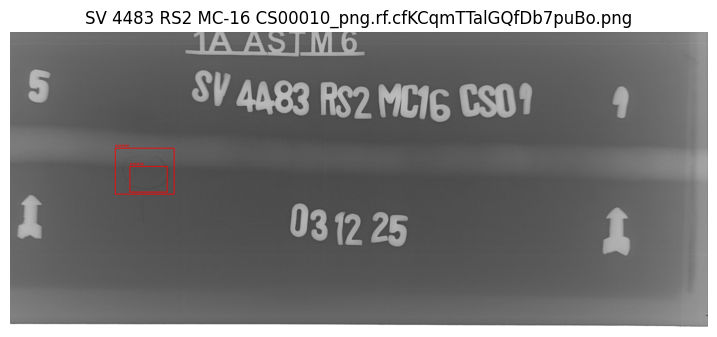

In [ ]:
def draw_final(image_path, detections, title=""):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for (x1, y1, x2, y2), score, cls_prob in detections:
        x1, y1, x2, y2 = int(x1*w), int(y1*h), int(x2*w), int(y2*h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img, f"{score:.2f}/{cls_prob:.2f}", (x1, max(y1-8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    plt.figure(figsize=(9, 7)); plt.imshow(img); plt.title(title); plt.axis("off"); plt.show()

test_img_dir = os.path.join(CFG["raw_dir"], "test", "images")
test_images = [os.path.join(test_img_dir, f) for f in os.listdir(test_img_dir)][:6]
for p in test_images:
    dets = ensemble_predict(p)
    draw_final(p, dets, os.path.basename(p))


In [ ]:
def iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(ix2-ix1, 0), max(iy2-iy1, 0)
    inter = iw*ih
    area_a = max(ax2-ax1, 0) * max(ay2-ay1, 0)
    area_b = max(bx2-bx1, 0) * max(by2-by1, 0)
    union = area_a + area_b - inter
    return inter/union if union > 0 else 0.0

def gt_boxes_norm(label_path):
    boxes = []
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                p = line.split()
                if len(p) != 5:
                    continue
                _, xc, yc, bw, bh = map(float, p)
                boxes.append((xc-bw/2, yc-bh/2, xc+bw/2, yc+bh/2))
    return boxes

def evaluate_on_test(predict_fn, iou_thr=0.5, score_key=lambda d: d[1]):
    test_img_dir = os.path.join(CFG["raw_dir"], "test", "images")
    test_lbl_dir = os.path.join(CFG["raw_dir"], "test", "labels")
    tp = fp = fn = 0
    img_correct = 0
    n_images = 0
    for f in os.listdir(test_img_dir):
        if not f.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        n_images += 1
        img_path = os.path.join(test_img_dir, f)
        gt = gt_boxes_norm(os.path.join(test_lbl_dir, os.path.splitext(f)[0] + ".txt"))
        preds = predict_fn(img_path)
        matched_gt = set()
        image_ok = True
        for det in preds:
            box = det[0]
            best_iou, best_j = 0, -1
            for j, g in enumerate(gt):
                if j in matched_gt:
                    continue
                i = iou_xyxy(box, g)
                if i > best_iou:
                    best_iou, best_j = i, j
            if best_iou >= iou_thr:
                tp += 1
                matched_gt.add(best_j)
            else:
                fp += 1
        fn += len(gt) - len(matched_gt)
        image_has_defect = len(gt) > 0
        image_detected = len(matched_gt) > 0 if image_has_defect else len(preds) == 0
        img_correct += int(image_detected)

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2*precision*recall / (precision+recall) if (precision+recall) else 0.0
    image_acc = img_correct / n_images if n_images else 0.0
    return dict(precision=precision, recall=recall, f1=f1, image_level_accuracy=image_acc,
                tp=tp, fp=fp, fn=fn, n_test_images=n_images)

print("Evaluation utilities ready.")


Evaluation utilities ready.


In [ ]:
def predict_a(path):
    boxes, scores, _ = sahi_boxes(det_a, path)
    return [(b, s, 1.0) for b, s in zip(boxes, scores) if s >= 0.25]

def predict_b(path):
    boxes, scores, _ = sahi_boxes(det_b, path)
    return [(b, s, 1.0) for b, s in zip(boxes, scores) if s >= 0.25]

def predict_ensemble(path):
    return ensemble_predict(path)

results = {}
for name, fn in [("YOLO11n (SAHI)", predict_a), ("YOLO11s (SAHI)", predict_b), ("Ensemble + ResNet filter", predict_ensemble)]:
    r = evaluate_on_test(fn)
    results[name] = r
    print(f"\n{name}")
    print(f"  Precision={r['precision']:.3f}  Recall={r['recall']:.3f}  F1={r['f1']:.3f}")
    print(f"  Image-level accuracy={r['image_level_accuracy']:.3f}  (on {r['n_test_images']} test images)")



YOLO11n (SAHI)
  Precision=0.000  Recall=0.000  F1=0.000
  Image-level accuracy=0.000  (on 1 test images)

YOLO11s (SAHI)
  Precision=0.000  Recall=0.000  F1=0.000
  Image-level accuracy=0.000  (on 1 test images)

Ensemble + ResNet filter
  Precision=0.000  Recall=0.000  F1=0.000
  Image-level accuracy=0.000  (on 1 test images)


### Upload an image for prediction

In [ ]:
# Upload the image you want to test
from google.colab import files
import io

uploaded_files = files.upload()

# Assuming only one file is uploaded
for filename, content in uploaded_files.items():
    # Save the uploaded file to a temporary location
    test_image_path = os.path.join("/tmp", filename)
    with open(test_image_path, "wb") as f:
        f.write(content)
    print(f"Uploaded file saved to: {test_image_path}")
    break # Process only the first uploaded file

Saving GY HS200 JM MCW-106 00004_png.rf.vaNG1RVo4yGXYfmGJSKZ_zoom256_b0_x1944_y762.jpg to GY HS200 JM MCW-106 00004_png.rf.vaNG1RVo4yGXYfmGJSKZ_zoom256_b0_x1944_y762.jpg
Uploaded file saved to: /tmp/GY HS200 JM MCW-106 00004_png.rf.vaNG1RVo4yGXYfmGJSKZ_zoom256_b0_x1944_y762.jpg


### YOLO Bounding Box Detections

Running ensemble prediction for: GY HS200 JM MCW-106 00004_png.rf.vaNG1RVo4yGXYfmGJSKZ_zoom256_b0_x1944_y762.jpg
Found 1 potential defects.


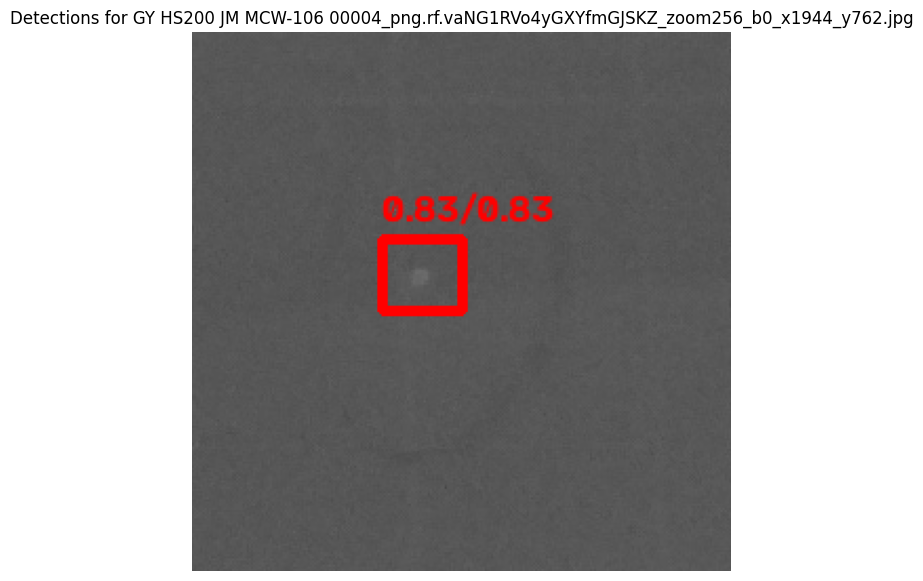

In [ ]:
if 'test_image_path' in locals() and os.path.exists(test_image_path):
    print(f"Running ensemble prediction for: {os.path.basename(test_image_path)}")
    detections = ensemble_predict(test_image_path)
    if detections:
        print(f"Found {len(detections)} potential defects.")
        draw_final(test_image_path, detections, f"Detections for {os.path.basename(test_image_path)}")
    else:
        print("No defects detected by the ensemble model. Displaying original image.")
        # Display the original image if no defects are found
        show_with_boxes(test_image_path, "", f"Original image: {os.path.basename(test_image_path)}")
else:
    print("Please upload an image in the previous step to perform YOLO detection.")

##FULL IMAGE -> PATCHES->FIND-> SAHI->FULL IMAGE

Upload a weld image to check for defects:


Saving SV 2208 DA 01 TSS LS C-D.tif to SV 2208 DA 01 TSS LS C-D (1).tif

Uploaded: /content/SV 2208 DA 01 TSS LS C-D (1).tif


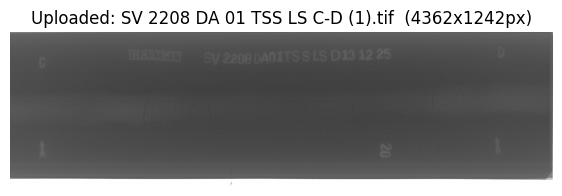

In [ ]:
from google.colab import files

print("Upload a weld image to check for defects:")
uploaded_files = files.upload()

test_image_path = None
if uploaded_files:
    filename = list(uploaded_files.keys())[0]
    test_image_path = os.path.join("/content", filename)
    with open(test_image_path, "wb") as f:
        f.write(uploaded_files[filename])
    print(f"\nUploaded: {test_image_path}")

    # quick preview of the raw upload before patching/detection
    preview = cv2.cvtColor(cv2.imread(test_image_path), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(7, 6))
    plt.imshow(preview)
    plt.title(f"Uploaded: {filename}  ({preview.shape[1]}x{preview.shape[0]}px)")
    plt.axis("off")
    plt.show()
else:
    print("No file uploaded.")

In [ ]:
# ---- Load the trained ensemble directly with Ultralytics (no SAHI) ----
# SAHI's own confidence gating + slicing was silently dropping detections on
# fresh uploads. Doing the patching ourselves gives full control and lets us
# actually SEE what happened on every single patch.

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
import math

patch_model_a = YOLO(f"{RUNS_DIR}/yolo11n_v2/weights/best.pt")

PATCH_MODELS  = [patch_model_a]   # add/remove models here to change the ensemble

# --- tuning knobs ---
PATCH_TILE_SIZE  = 640     # matches the tile size used most during training
PATCH_OVERLAP    = 0.25    # 25% overlap between neighbouring tiles (avoids missing edge defects)
PATCH_CONF       = 0.10    # per-patch confidence threshold BEFORE fusion (keep low, fusion cleans up)
WBF_IOU_THR      = 0.5     # IoU at which two boxes (from overlapping tiles/models) are merged
FINAL_SCORE_THR  = 0.25    # confidence threshold for what actually gets drawn on the final image

print("Ensemble loaded:", [type(m).__name__ for m in PATCH_MODELS], "->", len(PATCH_MODELS), "model(s)")


Ensemble loaded: ['YOLO'] -> 1 model(s)


In [ ]:
def make_patch_grid(w, h, tile_size=PATCH_TILE_SIZE, overlap=PATCH_OVERLAP):
    """Compute (x, y, x_end, y_end) tiles that fully cover a w x h image.
    The NUMBER of tiles is derived from the image's own width/height, so a
    small image gets 1 tile and a large one automatically gets a full grid."""
    stride = max(int(tile_size * (1 - overlap)), 1)
    xs = list(range(0, max(w - tile_size, 0) + 1, stride)) or [0]
    ys = list(range(0, max(h - tile_size, 0) + 1, stride)) or [0]
    if w > tile_size and xs[-1] != w - tile_size:
        xs.append(w - tile_size)
    if h > tile_size and ys[-1] != h - tile_size:
        ys.append(h - tile_size)
    grid = []
    for y in ys:
        for x in xs:
            x_end, y_end = min(x + tile_size, w), min(y + tile_size, h)
            grid.append((x, y, x_end, y_end))
    return grid


def detect_defects_in_large_image(image_path, tile_size=PATCH_TILE_SIZE,
                                   overlap=PATCH_OVERLAP, patch_conf=PATCH_CONF,
                                   wbf_iou_thr=WBF_IOU_THR, final_thr=FINAL_SCORE_THR,
                                   show_patches=True):
    """1) split the image into patches sized to its own dimensions
       2) run every model on every patch and box any defect found IN that patch
       3) map every patch-local box back to full-image coordinates
       4) fuse duplicate boxes coming from overlapping tiles / different models
       5) return the fused detections, ready to be drawn on the stitched full image
    """
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(image_path)
    h, w = img.shape[:2]
    grid = make_patch_grid(w, h, tile_size, overlap)
    print(f"Image {os.path.basename(image_path)}: {w}x{h}px -> {len(grid)} patch(es) "
          f"of ~{tile_size}px, {int(overlap*100)}% overlap")

    boxes_per_model  = [[] for _ in PATCH_MODELS]   # normalized full-image coords
    scores_per_model = [[] for _ in PATCH_MODELS]
    patch_records = []

    for (x, y, x_end, y_end) in grid:
        tile = img[y:y_end, x:x_end]
        tile_dets_for_viz = []
        for mi, model in enumerate(PATCH_MODELS):
            res = model.predict(tile, conf=patch_conf, verbose=False)[0]
            for b in res.boxes:
                bx1, by1, bx2, by2 = b.xyxy[0].tolist()
                conf = float(b.conf[0])
                gx1, gy1, gx2, gy2 = x + bx1, y + by1, x + bx2, y + by2   # patch -> global pixels
                boxes_per_model[mi].append([gx1 / w, gy1 / h, gx2 / w, gy2 / h])
                scores_per_model[mi].append(conf)
                tile_dets_for_viz.append((bx1, by1, bx2, by2, conf))
        patch_records.append(dict(x=x, y=y, tile=tile, dets=tile_dets_for_viz))

    # ---- show every patch, with any defect boxed right there on that patch ----
    if show_patches:
        cols = min(4, len(patch_records))
        rows = math.ceil(len(patch_records) / cols)
        plt.figure(figsize=(4 * cols, 4 * rows))
        for i, rec in enumerate(patch_records, start=1):
            vis = cv2.cvtColor(rec["tile"], cv2.COLOR_BGR2RGB).copy()
            for (bx1, by1, bx2, by2, conf) in rec["dets"]:
                cv2.rectangle(vis, (int(bx1), int(by1)), (int(bx2), int(by2)), (255, 0, 0), 2)
                cv2.putText(vis, f"{conf:.2f}", (int(bx1), max(int(by1) - 6, 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
            plt.subplot(rows, cols, i)
            plt.imshow(vis)
            tag = "DEFECT" if rec["dets"] else "clean"
            plt.title(f"patch {i} [{tag}]", fontsize=9)
            plt.axis("off")
        plt.tight_layout()
        plt.show()

    # ---- fuse duplicate boxes from overlapping patches / different models ----
    if not any(len(b) for b in boxes_per_model):
        print("No defects detected in any patch.")
        return [], (h, w)

    labels_per_model = [[0] * len(s) for s in scores_per_model]
    boxes_per_model  = [b if b else [[0, 0, 0, 0]] for b in boxes_per_model]
    scores_per_model = [s if s else [0.0] for s in scores_per_model]
    labels_per_model = [l if l else [0] for l in labels_per_model]

    fused_boxes, fused_scores, _ = weighted_boxes_fusion(
        boxes_per_model, scores_per_model, labels_per_model,
        weights=[1] * len(PATCH_MODELS), iou_thr=wbf_iou_thr, skip_box_thr=0.001)

    detections = [(box, float(score)) for box, score in zip(fused_boxes, fused_scores)
                  if score >= final_thr]
    return detections, (h, w)


In [ ]:
def draw_final_stitched(image_path, detections, hw, title=""):
    """Draw every fused detection back onto the ORIGINAL, full-resolution image
    (i.e. the patches, "stitched" back together with their boxes in the right place)."""
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = hw
    for (x1, y1, x2, y2), score in detections:
        x1, y1, x2, y2 = int(x1 * w), int(y1 * h), int(x2 * w), int(y2 * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img, f"defect {score:.2f}", (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()
    return img


In [ ]:
# ---- OPTIONAL DIAGNOSTIC: see every raw box BEFORE the final_thr cutoff ----
# Useful if the final image comes back empty: it tells you whether the models
# saw *nothing* at all, or saw something but just below FINAL_SCORE_THR.
if 'test_image_path' in locals() and os.path.exists(test_image_path):
    img_dbg = cv2.imread(test_image_path)
    h_dbg, w_dbg = img_dbg.shape[:2]
    grid_dbg = make_patch_grid(w_dbg, h_dbg)
    for mi, model in enumerate(PATCH_MODELS):
        all_scores = []
        for (x, y, x_end, y_end) in grid_dbg:
            tile = img_dbg[y:y_end, x:x_end]
            res = model.predict(tile, conf=0.001, verbose=False)[0]
            all_scores += [float(b.conf[0]) for b in res.boxes]
        all_scores.sort(reverse=True)
        print(f"model {mi} ({type(model).__name__} @ {model.ckpt_path if hasattr(model,'ckpt_path') else ''}): "
              f"{len(all_scores)} raw boxes across {len(grid_dbg)} patches, top5={[f'{s:.3f}' for s in all_scores[:5]]}")
else:
    print("Upload an image first.")


model 0 (YOLO @ /content/RUNS_V2/yolo11n_v2/weights/best.pt): 402 raw boxes across 27 patches, top5=['0.836', '0.829', '0.798', '0.792', '0.760']


Image SV 2208 DA 01 TSS LS C-D (1).tif: 4362x1242px -> 27 patch(es) of ~640px, 25% overlap


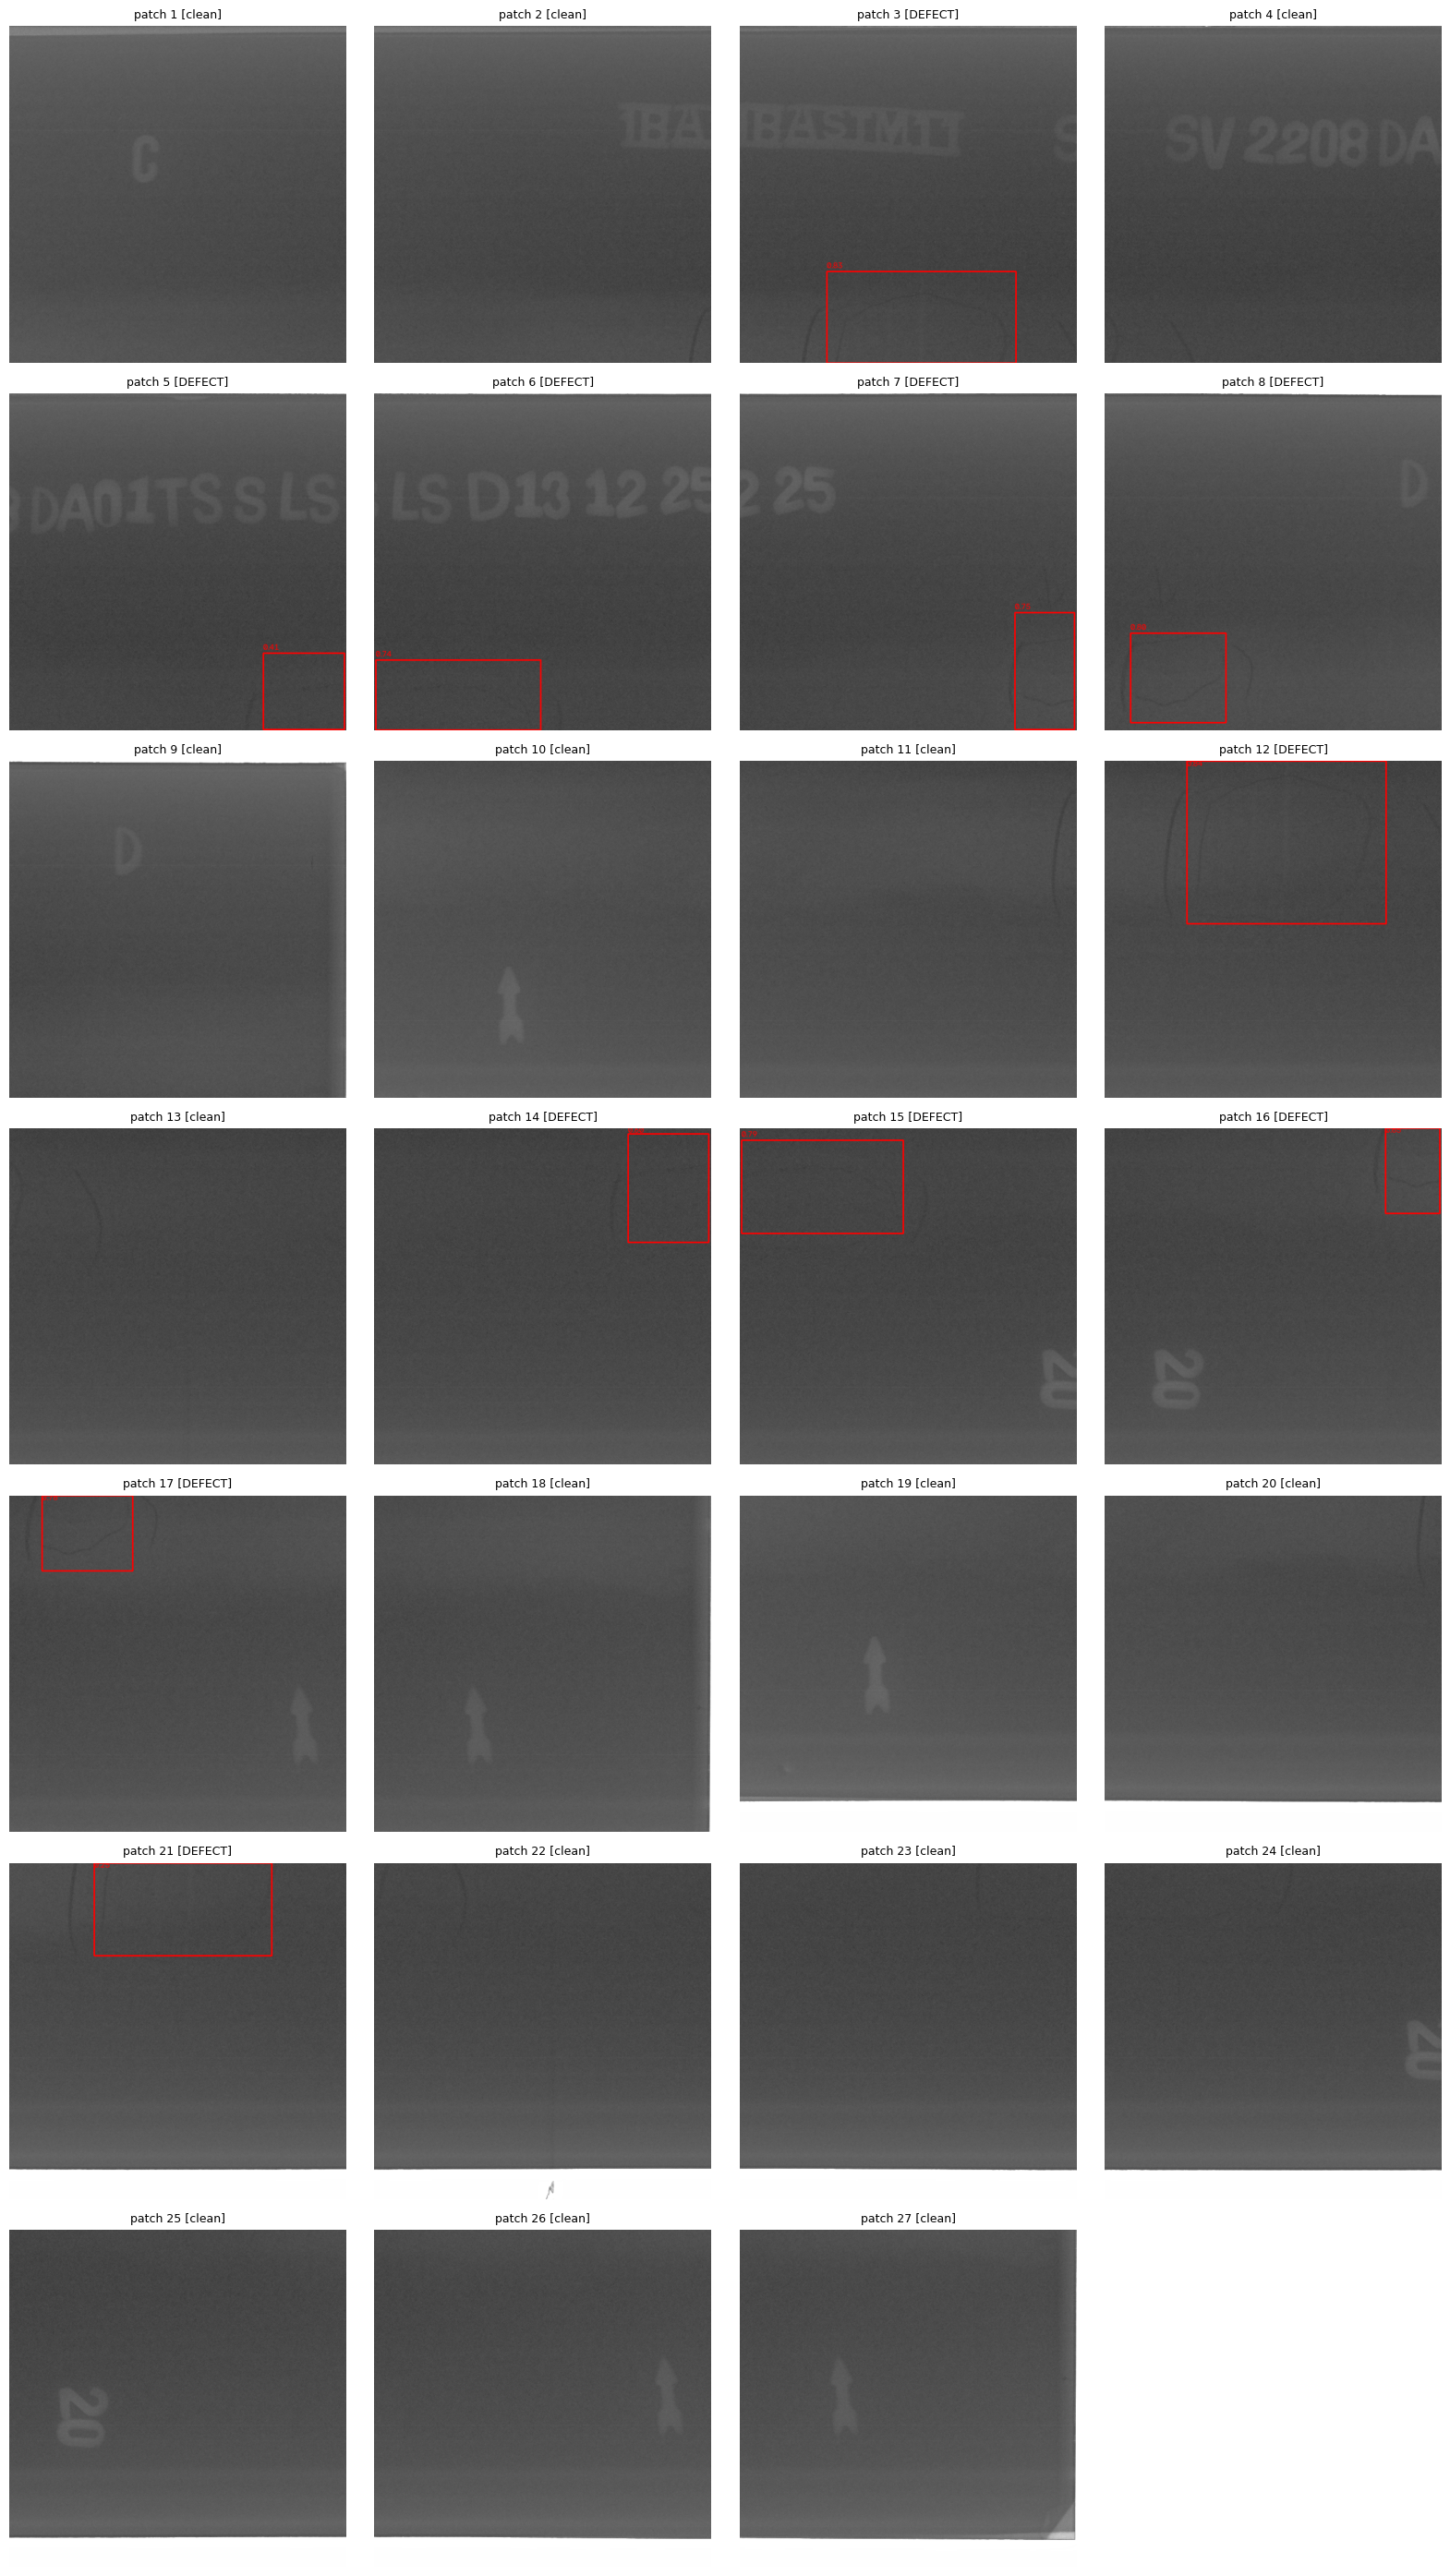


Found 6 defect(s) after patch-wise detection + stitching.


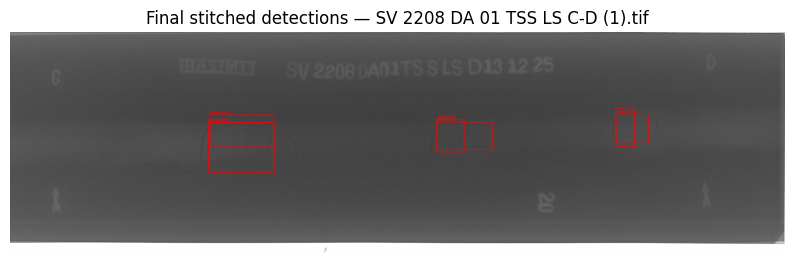

In [ ]:
if 'test_image_path' in locals() and os.path.exists(test_image_path):
    detections, hw = detect_defects_in_large_image(test_image_path)
    print(f"\nFound {len(detections)} defect(s) after patch-wise detection + stitching.")
    draw_final_stitched(test_image_path, detections, hw,
                         f"Final stitched detections — {os.path.basename(test_image_path)}")
else:
    print("Please upload an image first.")


In [ ]:
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── CONFIG ─────────────────────────────────────────────────────────────────
# Pixel coordinates (x, y) of checkpoint D on the FULL image.
# You can click on the image in any viewer (e.g. PIL/matplotlib) to read the
# coordinates, or enter them manually from the bounding-box printout above.
CHECKPOINT_D = (50, 50)       # ← change this to your actual checkpoint pixel

# Physical calibration: how many pixels equal 1 mm?
# Set to None to skip mm conversion and report pixel distances only.
PIXELS_PER_MM = None          # e.g. 10.5  (measure a known feature to calibrate)
# ───────────────────────────────────────────────────────────────────────────


def defect_centre_pixels(box_norm, hw):
    """Convert a normalised (x1,y1,x2,y2) box to the pixel centre (cx, cy)."""
    h, w = hw
    x1, y1, x2, y2 = box_norm
    cx = ((x1 + x2) / 2) * w
    cy = ((y1 + y2) / 2) * h
    return cx, cy


def euclidean_distance(p1, p2):
    """Pixel Euclidean distance between two (x, y) points."""
    return math.sqrt((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2)


def compute_defect_distances(detections, hw, checkpoint_d, pixels_per_mm=None):
    """
    Args:
        detections   : list of (box_norm, score) tuples from detect_defects_in_large_image
        hw           : (height, width) of the full image in pixels
        checkpoint_d : (x, y) pixel coordinate of point D
        pixels_per_mm: calibration factor; None → mm column omitted

    Returns:
        List of dicts with keys: defect_id, centre_px, dist_px, dist_mm (optional), score, box_norm
    """
    records = []
    for idx, (box_norm, score) in enumerate(detections, start=1):
        cx, cy = defect_centre_pixels(box_norm, hw)
        dist_px = euclidean_distance(checkpoint_d, (cx, cy))
        rec = dict(
            defect_id  = idx,
            centre_px  = (round(cx, 1), round(cy, 1)),
            dist_px    = round(dist_px, 2),
            score      = round(score, 4),
            box_norm   = box_norm,
        )
        if pixels_per_mm:
            rec["dist_mm"] = round(dist_px / pixels_per_mm, 3)
        records.append(rec)
    # sort nearest-first
    records.sort(key=lambda r: r["dist_px"])
    return records


# ── Run ────────────────────────────────────────────────────────────────────
if 'detections' not in dir() or detections is None:
    print("⚠  Run the detection cell above first so that `detections` and `hw` are available.")
else:
    dist_records = compute_defect_distances(detections, hw, CHECKPOINT_D, PIXELS_PER_MM)

    print(f"Checkpoint D : pixel {CHECKPOINT_D}")
    print(f"Defects found: {len(dist_records)}")
    print()

    # pretty table header
    header = f"{'#':>3}  {'Centre (px)':>18}  {'Dist (px)':>10}  {'Conf':>6}"
    if PIXELS_PER_MM:
        header += f"  {'Dist (mm)':>10}"
    print(header)
    print("-" * len(header))

    for r in dist_records:
        row = (f"{r['defect_id']:>3}  {str(r['centre_px']):>18}  "
               f"{r['dist_px']:>10.2f}  {r['score']:>6.4f}")
        if PIXELS_PER_MM:
            row += f"  {r['dist_mm']:>10.3f}"
        print(row)

    if dist_records:
        nearest = dist_records[0]
        print(f"\n→ Nearest defect: #{nearest['defect_id']} at {nearest['dist_px']:.1f} px from D", end="")
        if PIXELS_PER_MM:
            print(f" ({nearest['dist_mm']:.2f} mm)", end="")
        print()

Checkpoint D : pixel (50, 50)
Defects found: 6

  #         Centre (px)   Dist (px)    Conf
-------------------------------------------
  1  (np.float64(1305.3), np.float64(553.2))     1352.40  0.8293
  5  (np.float64(1301.8), np.float64(647.9))     1387.31  0.5444
  6  (np.float64(2479.1), np.float64(583.4))     2486.96  0.5068
  3  (np.float64(2558.4), np.float64(583.2))     2564.46  0.7654
  4  (np.float64(3461.8), np.float64(543.9))     3447.36  0.6975
  2  (np.float64(3504.3), np.float64(546.7))     3489.80  0.7789

→ Nearest defect: #1 at 1352.4 px from D


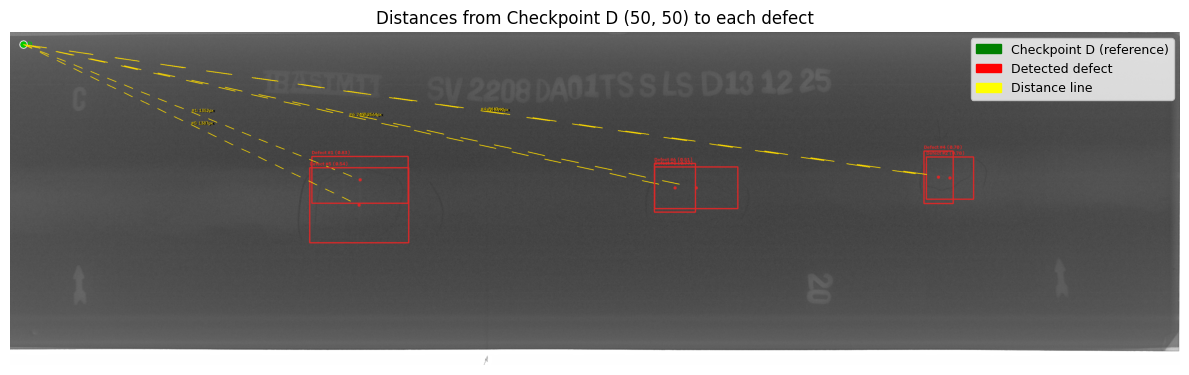

In [ ]:
# ── Visualise: draw D and distance lines on the full image ─────────────────
def draw_distances(image_path, dist_records, hw, checkpoint_d):
    """
    Annotates the full-resolution image with:
    - A green circle at checkpoint D
    - A red bounding box + centre dot for each defect
    - A dashed yellow line from D to each defect centre, labelled with the distance
    """
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = hw
    dx, dy = int(checkpoint_d[0]), int(checkpoint_d[1])

    # Draw checkpoint D
    cv2.circle(img, (dx, dy), 12, (0, 200, 0), -1)          # filled green circle
    cv2.circle(img, (dx, dy), 14, (255, 255, 255), 2)        # white outline
    cv2.putText(img, "D", (dx + 16, dy + 6),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 200, 0), 2, cv2.LINE_AA)

    for r in dist_records:
        x1, y1, x2, y2 = r["box_norm"]
        px1, py1 = int(x1 * w), int(y1 * h)
        px2, py2 = int(x2 * w), int(y2 * h)
        cx, cy   = int(r["centre_px"][0]), int(r["centre_px"][1])

        # Defect bounding box (red)
        cv2.rectangle(img, (px1, py1), (px2, py2), (220, 40, 40), 3)

        # Defect centre dot
        cv2.circle(img, (cx, cy), 6, (220, 40, 40), -1)

        # Dashed line from D to defect centre (draw as short segments)
        num_dashes = 20
        for seg in range(num_dashes):
            t_start = seg / num_dashes
            t_end   = (seg + 0.5) / num_dashes  # 50% dash, 50% gap
            lx1 = int(dx + (cx - dx) * t_start)
            ly1 = int(dy + (cy - dy) * t_start)
            lx2 = int(dx + (cx - dx) * t_end)
            ly2 = int(dy + (cy - dy) * t_end)
            cv2.line(img, (lx1, ly1), (lx2, ly2), (255, 220, 0), 2)

        # Distance label at the midpoint of the line
        mid_x = int((dx + cx) / 2)
        mid_y = int((dy + cy) / 2)
        dist_label = f"#{r['defect_id']}: {r['dist_px']:.0f}px"
        if "dist_mm" in r:
            dist_label += f" / {r['dist_mm']:.1f}mm"
        # drop shadow for readability
        cv2.putText(img, dist_label, (mid_x + 1, mid_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2, cv2.LINE_AA)
        cv2.putText(img, dist_label, (mid_x, mid_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 220, 0), 1, cv2.LINE_AA)

        # Defect label above the box
        cv2.putText(img, f"Defect #{r['defect_id']} ({r['score']:.2f})",
                    (px1, max(py1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (220, 40, 40), 2, cv2.LINE_AA)

    # Legend
    legend = [
        mpatches.Patch(color="green",  label="Checkpoint D (reference)"),
        mpatches.Patch(color="red",    label="Detected defect"),
        mpatches.Patch(color="yellow", label="Distance line"),
    ]
    plt.figure(figsize=(12, 9))
    plt.imshow(img)
    plt.legend(handles=legend, loc="upper right", fontsize=9, framealpha=0.8)
    plt.title(f"Distances from Checkpoint D {checkpoint_d} to each defect", fontsize=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    return img


if 'dist_records' in dir() and dist_records and 'test_image_path' in dir():
    annotated = draw_distances(test_image_path, dist_records, hw, CHECKPOINT_D)
elif 'dist_records' in dir() and not dist_records:
    print("No defects found — nothing to draw.")
else:
    print("Run the distance-computation cell above first.")

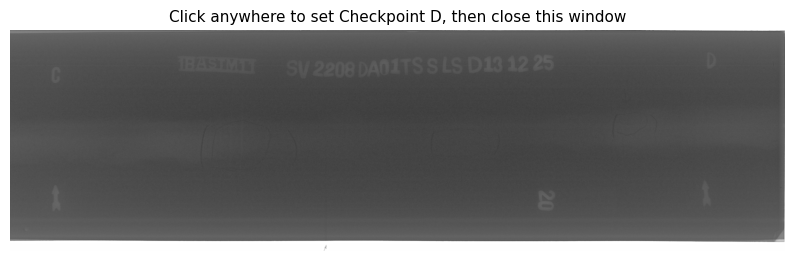

No click recorded. Run again and click on the image.


In [ ]:
# ── (Optional) Interactive checkpoint picker ────────────────────────────────
# Click on the image that appears below; the clicked pixel is recorded as D,
# then distances are recomputed and printed automatically.
# Requires matplotlib in inline / widget mode (works in Colab by default).

%matplotlib inline

if 'test_image_path' in dir() and os.path.exists(test_image_path) and 'detections' in dir():
    _img_rgb = cv2.cvtColor(cv2.imread(test_image_path), cv2.COLOR_BGR2RGB)
    _h, _w = _img_rgb.shape[:2]

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(_img_rgb)
    ax.set_title("Click anywhere to set Checkpoint D, then close this window", fontsize=11)
    ax.axis("off")

    _clicked = []

    def _on_click(event):
        if event.xdata is not None and event.ydata is not None:
            _clicked.clear()
            _clicked.append((int(event.xdata), int(event.ydata)))
            ax.set_title(f"Checkpoint D set to {_clicked[0]} — close window to continue", fontsize=11)
            # draw a marker so you can see where you clicked
            ax.plot(*_clicked[0], "go", markersize=12, label="D")
            fig.canvas.draw()

    fig.canvas.mpl_connect("button_press_event", _on_click)
    plt.show()

    if _clicked:
        CHECKPOINT_D = _clicked[0]
        print(f"\nCheckpoint D updated to: {CHECKPOINT_D}")
        # recompute and re-draw distances with the new D
        dist_records = compute_defect_distances(detections, hw, CHECKPOINT_D, PIXELS_PER_MM)
        for r in dist_records:
            line = f"  Defect #{r['defect_id']}  centre={r['centre_px']}  dist={r['dist_px']:.1f}px"
            if 'dist_mm' in r:
                line += f"  ({r['dist_mm']:.2f} mm)"
            print(line)
        annotated = draw_distances(test_image_path, dist_records, hw, CHECKPOINT_D)
    else:
        print("No click recorded. Run again and click on the image.")
else:
    print("Run detection first, then re-run this cell.")

In [ ]:
# ── Save trained weights + ensemble config for sharing ─────────────────────
import os, shutil, zipfile, json
from datetime import datetime

SAVE_DIR  = "/content/DRDO_WELDING_SAVED_MODELS"
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
ZIP_NAME  = f"drdo_welding_ensemble_{TIMESTAMP}.zip"

os.makedirs(SAVE_DIR, exist_ok=True)

# ── 1. Copy best.pt for each trained model ──────────────────────────────────
model_tags = {
    "yolo11n_v2": f"{RUNS_DIR}/yolo11n_v2/weights/best.pt",
    "yolo11s_v2": f"{RUNS_DIR}/yolo11s_v2/weights/best.pt",
}

saved_paths = {}
for tag, src in model_tags.items():
    if os.path.exists(src):
        dst = os.path.join(SAVE_DIR, f"{tag}_best.pt")
        shutil.copy2(src, dst)
        saved_paths[tag] = dst
        size_mb = os.path.getsize(dst) / 1e6
        print(f"✓  {tag}_best.pt  saved  ({size_mb:.1f} MB)")
    else:
        print(f"✗  {src} not found — skip (train this model first)")

# ── 2. Save data.yaml (needed to reload in the same class mapping) ─────────
data_yaml_src = os.path.join(CFG["final_dir"], "data.yaml")
if os.path.exists(data_yaml_src):
    shutil.copy2(data_yaml_src, os.path.join(SAVE_DIR, "data.yaml"))
    print("✓  data.yaml saved")

# ── 3. Save ensemble config as JSON ────────────────────────────────────────
ensemble_cfg = {
    "description"      : "DRDO Welding Defect Ensemble (YOLO11n + YOLO11s + WBF)",
    "created_at"       : TIMESTAMP,
    "models"           : list(model_tags.keys()),
    "weights"          : [1, 1],
    "patch_tile_size"  : PATCH_TILE_SIZE,
    "patch_overlap"    : PATCH_OVERLAP,
    "patch_conf"       : PATCH_CONF,
    "wbf_iou_thr"      : WBF_IOU_THR,
    "final_score_thr"  : FINAL_SCORE_THR,
    "class_names"      : CFG["class_names"],
    "usage": (
        "from ultralytics import YOLO; "
        "model_a = YOLO('yolo11n_v2_best.pt'); "
        "model_b = YOLO('yolo11s_v2_best.pt')"
    ),
}
cfg_path = os.path.join(SAVE_DIR, "ensemble_config.json")
with open(cfg_path, "w") as f:
    json.dump(ensemble_cfg, f, indent=2)
print("✓  ensemble_config.json saved")

# ── 4. Write a README ──────────────────────────────────────────────────────
readme = f"""DRDO Welding Defect Detection — Saved Models
============================================
Created : {TIMESTAMP}

Files
-----
yolo11n_v2_best.pt    — YOLO11n detector (lighter / faster)
yolo11s_v2_best.pt    — YOLO11s detector (slightly higher capacity)
data.yaml             — class mapping used during training
ensemble_config.json  — inference hyper-parameters for the WBF ensemble

Quick-start (Python)
--------------------
from ultralytics import YOLO
model = YOLO("yolo11n_v2_best.pt")          # or yolo11s_v2_best.pt
results = model.predict("weld_image.jpg", conf=0.25)
results[0].show()

To run the full patch-wise ensemble exactly as during evaluation,
copy the detect_defects_in_large_image() function from the notebook.

ONNX export (for deployment without PyTorch)
--------------------------------------------
model.export(format="onnx")   # produces yolo11n_v2_best.onnx
"""
with open(os.path.join(SAVE_DIR, "README.txt"), "w") as f:
    f.write(readme)
print("✓  README.txt written")

# ── 5. Zip everything ──────────────────────────────────────────────────────
zip_path = os.path.join("/content", ZIP_NAME)
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in os.listdir(SAVE_DIR):
        zf.write(os.path.join(SAVE_DIR, fname), arcname=fname)
size_mb = os.path.getsize(zip_path) / 1e6
print(f"\n✓  Zip created: {zip_path}  ({size_mb:.1f} MB)")
print("   Download it from the Colab file browser (left sidebar → Files).")

✓  yolo11n_v2_best.pt  saved  (5.5 MB)
✓  yolo11s_v2_best.pt  saved  (19.2 MB)
✓  data.yaml saved
✓  ensemble_config.json saved
✓  README.txt written

✓  Zip created: /content/drdo_welding_ensemble_20260909_164257.zip  (22.5 MB)
   Download it from the Colab file browser (left sidebar → Files).


In [ ]:
# ── Download the zip directly to your machine (Colab only) ─────────────────
from google.colab import files
files.download(zip_path)
print(f"Download triggered for: {ZIP_NAME}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered for: drdo_welding_ensemble_20260909_164257.zip


In [ ]:
# ── (Optional) Export to ONNX for framework-agnostic deployment ───────────
# Run AFTER the save cell above. Adds the .onnx files to the zip.

for tag, src_pt in model_tags.items():
    if not os.path.exists(src_pt):
        print(f"Skip {tag} — .pt not found")
        continue
    m = YOLO(src_pt)
    # export() writes model.onnx next to the .pt file
    onnx_path = m.export(format="onnx", imgsz=640, simplify=True)
    dst_onnx  = os.path.join(SAVE_DIR, f"{tag}_best.onnx")
    shutil.copy2(onnx_path, dst_onnx)
    size_mb = os.path.getsize(dst_onnx) / 1e6
    print(f"✓  {tag}_best.onnx  ({size_mb:.1f} MB)")

# Re-zip with the ONNX files included
zip_path_onnx = zip_path.replace(".zip", "_with_onnx.zip")
with zipfile.ZipFile(zip_path_onnx, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in os.listdir(SAVE_DIR):
        zf.write(os.path.join(SAVE_DIR, fname), arcname=fname)
size_mb = os.path.getsize(zip_path_onnx) / 1e6
print(f"\n✓  Updated zip with ONNX: {zip_path_onnx}  ({size_mb:.1f} MB)")
print("   Download from the Colab file browser (left sidebar → Files).")

Ultralytics 8.4.145 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/RUNS_V2/yolo11n_v2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 308ms
Prepared 4 packages in 2.05s
Installed 4 packages in 455ms
 + colorama==0.4.6
 + onnx==1.22.0
 + onnxruntime==1.29.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 3.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming w